# 05 — Analysis of the `d100k` run: 100,000 speeches, DeepSeek alone

**Preliminary — for discussion, not citation.**

Run `20261018T122536Z` (label `d100k`, `docs/decisions.md` S19): **99,996 floor
speeches, 1,923 per Congress × party × chamber** (107th–119th Congress, 2001–2025),
the S8 design at about 19 times the size, scored for ideology (−1 liberal … +1
conservative) and tone (0 neutral … 1 hostile) by **DeepSeek-V4.1-Flash-1017
alone**, thinking mode. GPT-4o was dropped for cost; on the S8 speeches the two
models agree at r = 0.94 (S19, notebook 04 section 8). Each speech also carries a
speech type and, for policy debate, a topic (label run `20261017T182223Z`, L1–L8).

The rules of notebook 04 hold: **House and Senate are never pooled**, **every
interval is clustered by member** (career-long ICPSR), and the **2016-09-10 source
break** is marked at the 114th Congress. With one model, a speech's "ensemble"
score is DeepSeek's score, and there is no per-speech disagreement measure.

The logic lives in `code/src/analysis.py`, `label_eval.py` and `plots.py` (tested);
this notebook only calls it. Figures go to `results/plots/d100k_*`, tables to
`results/metrics/d100k_*`. No API calls.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "code"))

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

from src.analysis import (
    attach_labels, cell_means, load_scored_run, member_means, party_gap, trend,
)
from src.config import METRICS_DIR, SCORES_DIR, SOURCE_BREAK_CONGRESS, SPEECH_TYPES
from src.label_eval import label_shares, procedural_crosstab, scores_by_type
from src.plots import (
    plot_gap, plot_label_shares, plot_member_validation, plot_party_positions,
    save_figure,
)
from src.runs import run_models

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)

RUN = "20261018T122536Z"        # d100k: 99,996 speeches, DeepSeek alone (S19)
LABEL_RUN = "20261017T182223Z"  # speech type and topic (L1-L8)
S8_RUN = "20261003T110419Z"     # S8: 5,200 of the same speeches, earlier DeepSeek build + GPT-4o

df = attach_labels(load_scored_run(RUN), LABEL_RUN)
(MODEL,) = run_models(SCORES_DIR, RUN)
print(f"{len(df):,} speeches, model {MODEL}; {df['ideology'].notna().sum():,} scored, "
      f"{df['speech_type'].notna().sum():,} labelled")

99,996 speeches, model deepseek-flash; 99,993 scored, 99,967 labelled


In [2]:
def with_ci(table, value="mean", digits=2):
    """'0.46 [0.35, 0.57]' -- a value with its 95% interval."""
    return table.apply(
        lambda r: f"{r[value]:+.{digits}f} [{r['ci_low']:+.{digits}f}, {r['ci_high']:+.{digits}f}]",
        axis=1,
    )

## 1. What was scored

In [3]:
summary = json.loads((METRICS_DIR / f"d100k_summary_{RUN}.json").read_text())
m = summary["per_model"][MODEL]
pd.Series({
    "answered by": ", ".join(m["served_models"]),
    "model builds (fingerprints)": ", ".join(f[:8] + "…" for f in m["system_fingerprints"]),
    "calls": f"{m['calls']:,}",
    "speeches without a score": m["failures"],
    "cost, USD (list price, peak)": round(m["cost_usd"], 2),
}).to_frame("d100k")

,d100k
answered by,deepseek-flash
model builds (fingerprints),e72d3c7f…
calls,"99,996"
speeches without a score,3
"cost, USD (list price, peak)",72.94


In [4]:
per_cell = df.groupby(["congress_number", "chamber", "party"]).size()
print(f"{len(per_cell)} cells of {per_cell.min():,}–{per_cell.max():,} speeches.")
print("Source of the sampled speeches per Congress (the 114th holds both):")
pd.crosstab(df["congress_number"], df["source"]).T

52 cells of 1,923–1,923 speeches.
Source of the sampled speeches per Congress (the 114th holds both):


congress_number,107,108,109,110,111,112,113,114,115,116,117,118,119
source,,,,,,,,,,,,,
govinfo,0,0,0,0,0,0,0,763,7692,7692,7692,7692,7692
stanford,7692,7692,7692,7692,7692,7692,7692,6929,0,0,0,0,0


**Reading it.** Every one of the 52 cells holds exactly 1,923 speeches. 99,993 are
scored (3 failed: two answers cut off at the 8,192-token cap, one unreadable) and
99,967 labelled, all from one DeepSeek build. The 114th Congress holds 763 govinfo
speeches (10% of it), all from its last four months.

## 2. Did the new DeepSeek build change the scores?

DeepSeek moved `deepseek-flash` to a new build on 2026-10-17 (S18); S8 was scored
by the earlier one. The `d100k` draw contains all 5,200 S8 speeches, so the two
builds — and GPT-4o — can be compared on identical speeches.

In [5]:
s8 = load_scored_run(S8_RUN)
pairs = s8[["speech_id", "party", "chamber", "source",
            "ideology_deepseek-flash", "ideology_gpt-4o-2024-11-20",
            "tone_deepseek-flash", "tone_gpt-4o-2024-11-20"]].rename(columns={
    "ideology_deepseek-flash": "ideology_old", "ideology_gpt-4o-2024-11-20": "ideology_gpt",
    "tone_deepseek-flash": "tone_old", "tone_gpt-4o-2024-11-20": "tone_gpt",
}).merge(
    df[["speech_id", "ideology", "tone"]].rename(columns={"ideology": "ideology_new", "tone": "tone_new"}),
    on="speech_id",
)
print(f"{len(pairs):,} speeches scored by all three")

def r(d, a, b):
    return round(d[a].corr(d[b]), 3)

groups = [("all", pairs), *pairs.groupby("party")]
pd.DataFrame({
    f"{dim}: {a} vs {b}": {g: r(d, f"{dim}_{a}", f"{dim}_{b}") for g, d in groups}
    for dim in ("ideology", "tone")
    for a, b in (("new", "old"), ("old", "gpt"), ("new", "gpt"))
}).T

5,200 speeches scored by all three


,all,D,R
ideology: new vs old,0.978,0.959,0.970
ideology: old vs gpt,0.940,0.884,0.914
ideology: new vs gpt,0.939,0.887,0.910
tone: new vs old,0.979,0.978,0.979
tone: old vs gpt,0.921,0.918,0.924
tone: new vs gpt,0.925,0.923,0.928


In [6]:
shift = pairs.assign(ideology=pairs["ideology_new"] - pairs["ideology_old"],
                     tone=pairs["tone_new"] - pairs["tone_old"])
print("Mean shift, new build minus old, by source, chamber and party:")
display(shift.groupby(["source", "chamber", "party"])[["ideology", "tone"]].mean().unstack("party").round(3))
print(f"Paired t-test, ideology: p = {stats.ttest_rel(pairs['ideology_new'], pairs['ideology_old']).pvalue:.2g}; "
      f"|difference| > 0.3 on {(shift['ideology'].abs() > 0.3).mean():.1%} of speeches")

Mean shift, new build minus old, by source, chamber and party:


ideology          tone       
party                   D      R      D      R
source   chamber                              
govinfo  H          0.019 -0.004 -0.016 -0.007
         S          0.003 -0.007 -0.009 -0.004
stanford H          0.023 -0.006 -0.006 -0.008
         S          0.016 -0.003 -0.003 -0.006

Paired t-test, ideology: p = 7.5e-05; |difference| > 0.3 on 1.8% of speeches


**Reading it.** On the same 5,200 speeches the new build agrees with the old one at
r = 0.978 (0.959 within Democrats, 0.970 within Republicans) — closer than either
build agrees with GPT-4o (0.94). The shift is small but systematic: the new build
puts Democrats 0.003–0.023 and Republicans 0.003–0.007 closer to the centre, so the
party gap is about 0.01–0.03 narrower (paired p < 0.001 at n = 5,200; 1.8% of
speeches move by more than 0.3). It is similar in both sources, so it does not touch
trends *within* this run, but **levels from `d100k` and S8 are not interchangeable**:
compare trends, not values, across runs.

## 3. RQ1 — How far apart are the parties?

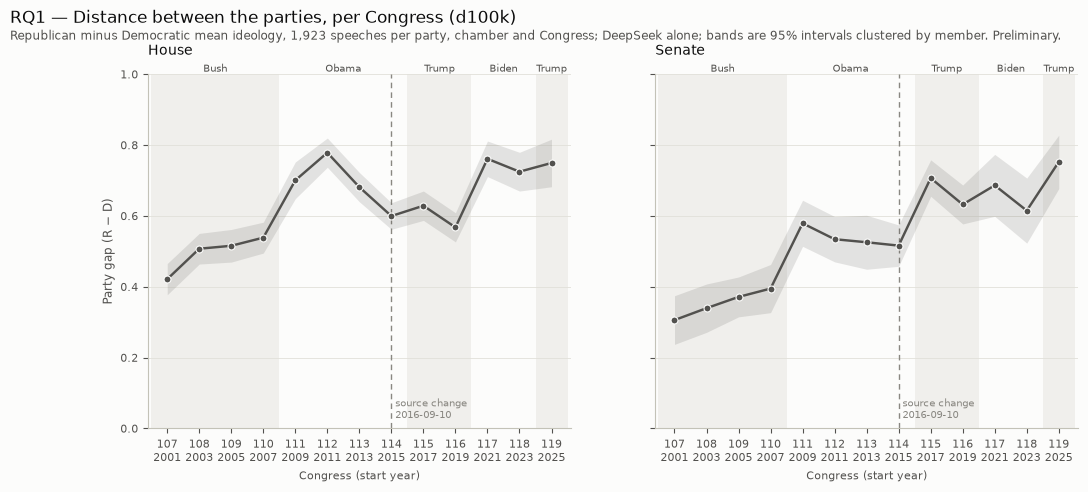

d100k (DeepSeek, new build)                        \
chamber                                   H                     S   
congress_number                                                     
107                    +0.42 [+0.38, +0.47]  +0.31 [+0.24, +0.37]   
108                    +0.51 [+0.46, +0.55]  +0.34 [+0.27, +0.41]   
109                    +0.52 [+0.47, +0.56]  +0.37 [+0.31, +0.43]   
110                    +0.54 [+0.49, +0.58]  +0.39 [+0.33, +0.46]   
111                    +0.70 [+0.65, +0.75]  +0.58 [+0.51, +0.64]   
112                    +0.78 [+0.74, +0.82]  +0.53 [+0.47, +0.60]   
113                    +0.68 [+0.64, +0.72]  +0.53 [+0.45, +0.60]   
114                    +0.60 [+0.56, +0.64]  +0.52 [+0.46, +0.57]   
115                    +0.63 [+0.59, +0.67]  +0.71 [+0.66, +0.76]   
116                    +0.57 [+0.53, +0.61]  +0.63 [+0.58, +0.69]   
117                    +0.76 [+0.71, +0.81]  +0.69 [+0.60, +0.77]   
118                    +0.72 [+0.67, +0.78]  +0.61 [+0.52, +0.71]   
119                    +0.75 [+0.68, +0.82]  +0.75 [+0.68, +0.83]   

                S8, DeepSeek (old build)       S8, two-model mean        
chamber                                H     S                  H     S  
congress_number                                                          
107                                 0.43  0.41               0.46  0.42  
108                                 0.55  0.35               0.58  0.38  
109                                 0.59  0.43               0.63  0.43  
110                                 0.60  0.40               0.65  0.45  
111                                 0.73  0.64               0.74  0.66  
112                                 0.86  0.56               0.89  0.59  
113                                 0.81  0.50               0.83  0.53  
114                                 0.52  0.53               0.56  0.56  
115                                 0.72  0.72               0.76  0.74  
116                                 0.55  0.69               0.63  0.75  
117                                 0.77  0.71               0.82  0.74  
118                                 0.70  0.65               0.73  0.68  
119                                 0.80  0.72               0.83  0.78

In [7]:
cells = cell_means(df)
gaps = party_gap(cells)
fig = plot_gap(
    gaps,
    "RQ1 — Distance between the parties, per Congress (d100k)",
    subtitle="Republican minus Democratic mean ideology, 1,923 speeches per party, chamber and Congress; DeepSeek alone; bands are 95% intervals clustered by member. Preliminary.",
)
save_figure(fig, "d100k_party_gap")
plt.show()

# Like for like: S8's DeepSeek scores (earlier build), and S8's two-model mean.
# GPT-4o puts the parties further apart than DeepSeek, so the levels differ by model.
gaps_s8_deepseek = party_gap(cell_means(s8, value="ideology_deepseek-flash"))
gaps_s8 = party_gap(cell_means(s8))
pd.concat({
    "d100k (DeepSeek, new build)": gaps.assign(g=with_ci(gaps, "gap")).pivot(index="congress_number", columns="chamber", values="g"),
    "S8, DeepSeek (old build)": gaps_s8_deepseek.pivot(index="congress_number", columns="chamber", values="gap").round(2),
    "S8, two-model mean": gaps_s8.pivot(index="congress_number", columns="chamber", values="gap").round(2),
}, axis=1)

**Reading it.** The gap widened in both chambers, but not in a straight line.
**House:** from 0.42 [0.38, 0.47] in the 107th to a peak of 0.78 [0.74, 0.82] in the
112th, down to 0.57–0.63 in the 114th–116th, back to 0.72–0.76 in the 117th–119th.
**Senate:** from 0.31 [0.24, 0.37] to about 0.55 in the 111th–114th, then a second
step to 0.71 [0.66, 0.76] in the 115th, and 0.75 [0.68, 0.83] in the 119th; that
second step coincides with the source change (section 5). The intervals are less
than half as wide as S8's, and the course follows S8's DeepSeek scores closely; the
levels sit a little lower, as section 2 explains, and GPT-4o puts the parties further
apart than DeepSeek does.

## 4. RQ2 — Which party moved?

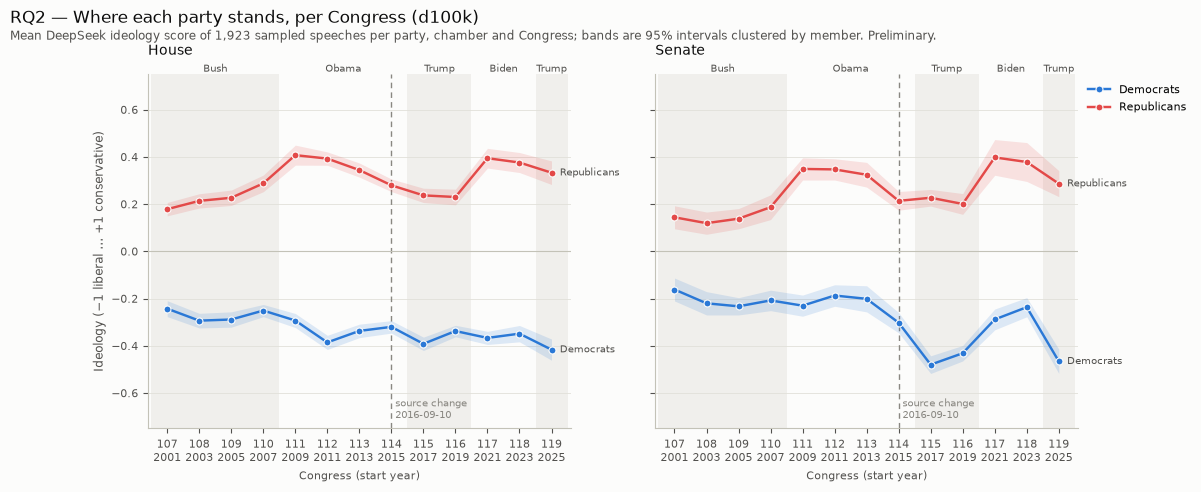

,window,chamber,party,span,slope_ci,change,p,n,n_members
0,"2001–2016, Stanford only",H,D,107-114,"-0.013 [-0.018, -0.008]",-0.09,4.9e-07,15384,410
1,"2001–2016, Stanford only",H,R,107-114,"+0.024 [+0.018, +0.029]",0.16,6.8e-16,15383,502
2,"2001–2016, Stanford only",S,D,107-114,"-0.009 [-0.016, -0.002]",-0.06,0.011,15384,98
3,"2001–2016, Stanford only",S,R,107-114,"+0.027 [+0.018, +0.037]",0.19,9.3e-09,15383,103
4,"2001–2025, both sources",H,D,107-119,"-0.011 [-0.014, -0.008]",-0.13,1.4e-10,24999,588
5,"2001–2025, both sources",H,R,107-119,"+0.010 [+0.005, +0.014]",0.12,2.3e-05,24997,702
6,"2001–2025, both sources",S,D,107-119,"-0.019 [-0.025, -0.013]",-0.23,1.3e-09,24999,125
7,"2001–2025, both sources",S,R,107-119,"+0.016 [+0.009, +0.022]",0.19,5.7e-06,24998,133


In [8]:
fig = plot_party_positions(
    cells,
    "Ideology (−1 liberal … +1 conservative)",
    "RQ2 — Where each party stands, per Congress (d100k)",
    subtitle="Mean DeepSeek ideology score of 1,923 sampled speeches per party, chamber and Congress; bands are 95% intervals clustered by member. Preliminary.",
    ylim=(-0.75, 0.75),
)
save_figure(fig, "d100k_party_positions")
plt.show()

def trend_table(data):
    t = pd.concat([
        trend(data, congress_range=(107, 114)).assign(window="2001–2016, Stanford only"),
        trend(data).assign(window="2001–2025, both sources"),
    ])
    return t, t.assign(
        slope_ci=with_ci(t, "slope", digits=3),
        change=t["change_over_span"].round(2),
        p=t["p"].map(lambda p: f"{p:.2g}"),
    )[["window", "chamber", "party", "span", "slope_ci", "change", "p", "n", "n_members"]].reset_index(drop=True)

trends, shown = trend_table(df)
shown

**Reading it.** **Both parties moved; Republicans about twice as far.** In the
single-source window (2001–2016) Republicans moved right by +0.16 in the House and
+0.19 in the Senate (both p < 10⁻⁸), Democrats left by −0.09 in the House
(p < 10⁻⁶) and −0.06 in the Senate (p = 0.01). S8 found the Republican move but
could not establish the Democratic one; with 19 times the speeches it is clear,
though smaller. Over the full window both move outward (Democrats −0.13 House, −0.23
Senate; Republicans +0.12, +0.19). The figure shows why a straight line is only a
summary: each party is most extreme while in opposition — Republicans under Obama
(111th–113th) and Biden (117th–118th), Democrats under Trump, above all in the Senate
(−0.48 in the 115th, −0.47 in the 119th; section 8).

**Policy debate only.** The same gap and trends on speeches labelled policy
debate, so procedural, ceremonial and other non-policy speech (near 0.0 for both
parties) neither dilutes the gap nor shapes its course.

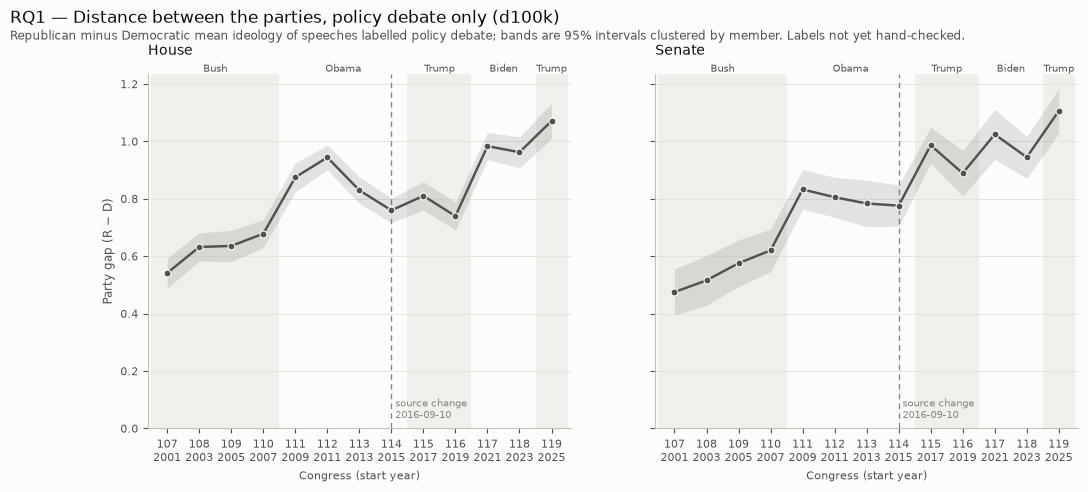

,window,chamber,party,span,slope_ci,change,p,n,n_members
0,"2001–2016, Stanford only",H,D,107-114,"-0.015 [-0.021, -0.009]",-0.10,8.1e-07,12086,404
1,"2001–2016, Stanford only",H,R,107-114,"+0.029 [+0.022, +0.036]",0.20,2.1e-17,11350,497
2,"2001–2016, Stanford only",S,D,107-114,"-0.013 [-0.021, -0.004]",-0.09,0.0035,9006,97
3,"2001–2016, Stanford only",S,R,107-114,"+0.041 [+0.027, +0.054]",0.28,1.5e-09,9446,103
4,"2001–2025, both sources",H,D,107-119,"-0.015 [-0.018, -0.011]",-0.18,4.2e-15,19377,580
5,"2001–2025, both sources",H,R,107-119,"+0.018 [+0.014, +0.023]",0.22,6.4e-17,17618,695
6,"2001–2025, both sources",S,D,107-119,"-0.023 [-0.028, -0.018]",-0.28,5.9e-21,15166,123
7,"2001–2025, both sources",S,R,107-119,"+0.027 [+0.019, +0.035]",0.32,6.4e-11,14989,132


In [9]:
policy = df[df["speech_type"] == "policy_debate"]
gaps_policy = party_gap(cell_means(policy))
fig = plot_gap(
    gaps_policy,
    "RQ1 — Distance between the parties, policy debate only (d100k)",
    subtitle="Republican minus Democratic mean ideology of speeches labelled policy debate; bands are 95% intervals clustered by member. Labels not yet hand-checked.",
)
save_figure(fig, "d100k_party_gap_policy_only")
plt.show()
trends_policy, shown = trend_table(policy)
shown

**Reading it.** In policy debate alone the trends are steeper and every one is
clear: 2001–2016 Republicans +0.20 (House) and +0.28 (Senate), Democrats −0.10 and
−0.09 (p ≤ 0.004 throughout); over the full window Democrats −0.18 / −0.28,
Republicans +0.22 / +0.32. Non-policy speech near 0.0 damps the trend; it does not
create it.

## 5. Does the 2016 source change shift the scores?

The 114th Congress holds both sources; govinfo covers only its last four months.

In [10]:
mixed = df[df["congress_number"] == SOURCE_BREAK_CONGRESS]
by_source = cell_means(mixed, by=("chamber", "party", "source"))
by_source.assign(mean_ci=with_ci(by_source))[["chamber", "party", "source", "n", "n_members", "mean_ci"]]

,chamber,party,source,n,n_members,mean_ci
0,H,D,govinfo,160,86,"-0.24 [-0.31, -0.18]"
1,H,D,stanford,1763,180,"-0.33 [-0.35, -0.30]"
2,H,R,govinfo,220,116,"+0.20 [+0.15, +0.24]"
3,H,R,stanford,1703,235,"+0.29 [+0.26, +0.32]"
4,S,D,govinfo,199,43,"-0.31 [-0.37, -0.25]"
5,S,D,stanford,1724,46,"-0.30 [-0.35, -0.26]"
6,S,R,govinfo,184,43,"+0.16 [+0.09, +0.23]"
7,S,R,stanford,1739,54,"+0.22 [+0.18, +0.26]"


**Reading it.** The 114th now holds 160–220 govinfo speeches per party and
chamber. They sit *closer* to the centre than the same Congress's Stanford speeches in
the House (Democrats −0.24 vs −0.33, Republicans +0.20 vs +0.29) and for Senate
Republicans (+0.16 vs +0.22); Senate Democrats are level (−0.31 vs −0.30). So there
is no sign that govinfo pushes scores outward — if anything the reverse — but its
114th speeches all come from September–December 2016 (the election and the lame-duck
session), so source and moment are still confounded.

## 6. Validation against DW-NOMINATE

Speech level from `validate_scores.py` (within-party rows are the real test, P5),
then member level (members with at least five sampled speeches; exploratory, O9).
The validation the thesis reports is A5's (member × Congress, within cells):
`validation_grid.py`.

In [11]:
val = json.loads((METRICS_DIR / f"validation_{RUN}.json").read_text())
rows = []
for subset, benchmarks in val["results"].items():
    for benchmark, columns in benchmarks.items():
        groups_ = columns.get(MODEL) or next(iter(columns.values()))
        rows.append({
            "speeches": subset, "benchmark": benchmark,
            **{
                group: f"{g['pearson_r']:+.2f} [{g['pearson_ci95'][0]:+.2f}, {g['pearson_ci95'][1]:+.2f}]"
                for group, g in groups_.items()
            },
        })
pd.DataFrame(rows).rename(columns={"all": "both parties", "D": "within D", "R": "within R"})

,speeches,benchmark,both parties,within D,within R
0,all_speeches,nominate_dim1,"+0.65 [+0.65, +0.66]","+0.24 [+0.23, +0.25]","+0.29 [+0.28, +0.30]"
1,all_speeches,nokken_poole_dim1,"+0.65 [+0.65, +0.65]","+0.23 [+0.22, +0.24]","+0.29 [+0.28, +0.30]"
2,non_procedural,nominate_dim1,"+0.80 [+0.80, +0.81]","+0.24 [+0.23, +0.25]","+0.32 [+0.31, +0.33]"
3,non_procedural,nokken_poole_dim1,"+0.80 [+0.80, +0.80]","+0.23 [+0.22, +0.24]","+0.32 [+0.31, +0.33]"


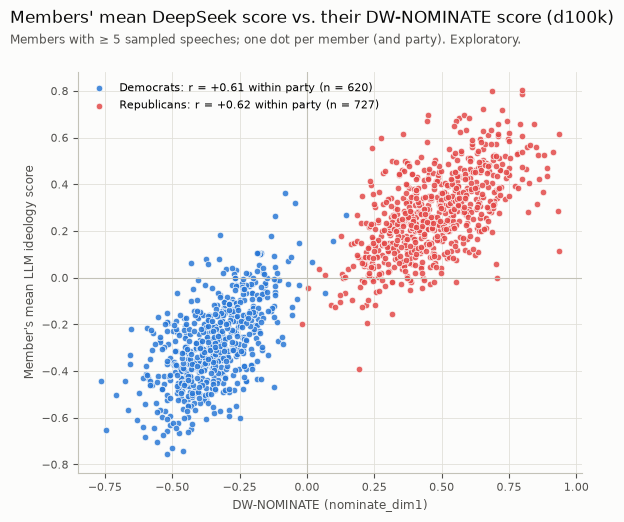

,nominate_dim1,nokken_poole_dim1
D,0.61,0.63
R,0.62,0.62
n members,1347.00,1347.00


In [12]:
members = member_means(df, min_speeches=5)
fig = plot_member_validation(
    members,
    title="Members' mean DeepSeek score vs. their DW-NOMINATE score (d100k)",
    subtitle="Members with ≥ 5 sampled speeches; one dot per member (and party). Exploratory.",
)
save_figure(fig, "d100k_member_validation")
plt.show()

pd.DataFrame({
    benchmark: {
        party: round(m_["ideology"].corr(m_[benchmark]), 2) for party, m_ in members.groupby("party")
    } | {"n members": len(members)}
    for benchmark in ("nominate_dim1", "nokken_poole_dim1")
})

**Reading it.** Speech level: r = 0.65 across parties (0.80 without speeches scored
0.0), 0.24 within Democrats and 0.29 within Republicans (0.32 without the 0.0
speeches); both benchmarks agree. Member level is much stronger and now rests on
1,347 members with at least five sampled speeches: **r = 0.61 (D) and 0.62 (R)**
against `nominate_dim1`, 0.63 / 0.62 against Nokken-Poole — up from 0.51 / 0.55 on
S8's 298 members. Averaged over their speeches, members line up within their party
much as their votes do. Which unit and benchmark the thesis uses was open here (O9); A5 (2026-10-22)
settled it: member × Congress means, Nokken-Poole, within cells, r = 0.54 [0.48, 0.59].

## 7. RQ5 — Has the tone become more hostile?

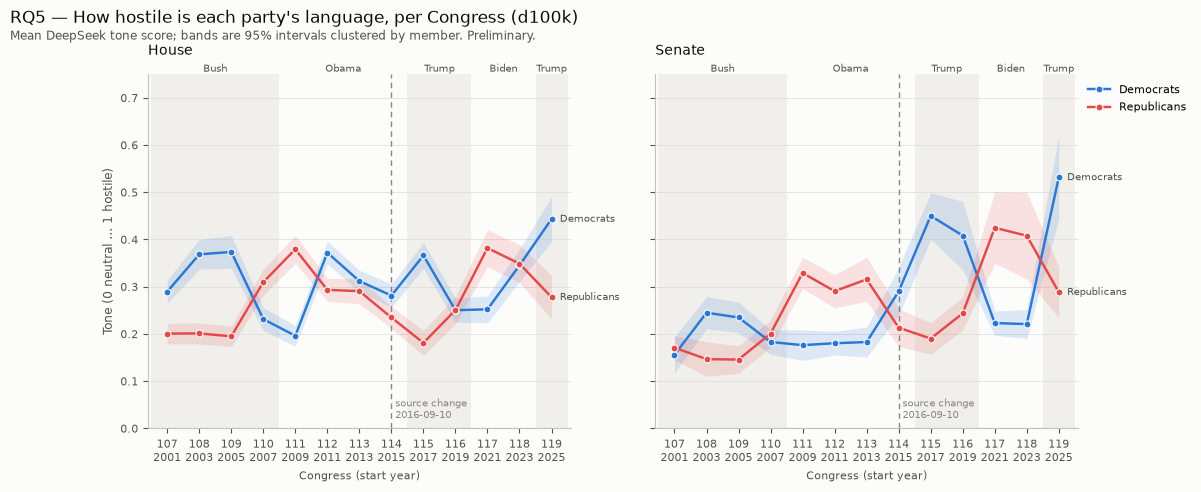

role           holds the presidency         in opposition
chamber party                                            
H       D      +0.29 [+0.27, +0.31]  +0.33 [+0.31, +0.35]
        R      +0.23 [+0.22, +0.25]  +0.32 [+0.30, +0.34]
S       D      +0.21 [+0.19, +0.23]  +0.32 [+0.27, +0.36]
        R      +0.20 [+0.17, +0.22]  +0.33 [+0.30, +0.36]

In [13]:
tone_cells = cell_means(df, value="tone")
fig = plot_party_positions(
    tone_cells,
    "Tone (0 neutral … 1 hostile)",
    "RQ5 — How hostile is each party's language, per Congress (d100k)",
    subtitle="Mean DeepSeek tone score; bands are 95% intervals clustered by member. Preliminary.",
    ylim=(0, 0.75),
)
save_figure(fig, "d100k_tone_positions")
plt.show()

opposition = cell_means(df, value="tone", by=("chamber", "party", "in_opposition"))
opposition.assign(
    role=opposition["in_opposition"].map({True: "in opposition", False: "holds the presidency"}),
    tone=with_ci(opposition),
).pivot(index=["chamber", "party"], columns="role", values="tone")

In [14]:
print("Spearman correlation of tone with |ideology|, policy debates only:")
pd.DataFrame({
    party: {"rho": round(stats.spearmanr(d["tone"], d["ideology"].abs()).statistic, 2), "n": len(d)}
    for party, d in policy.dropna(subset=["tone", "ideology"]).groupby("party")
}).T

Spearman correlation of tone with |ideology|, policy debates only:


,rho,n
D,0.59,34543.0
R,0.70,32607.0


**Reading it.** Tone is clearly higher in opposition in all four party-chamber cells
(House Democrats 0.29 → 0.33, House Republicans 0.23 → 0.32, Senate Democrats
0.21 → 0.32, Senate Republicans 0.20 → 0.33). The highest values are Democrats in
2025 (0.44 House, 0.53 Senate). Among policy debates tone rises with ideological
extremity (Spearman 0.59 D, 0.70 R) — with notebook 04's caveat: one model scores both
from the same text.

## 8. RQ3 — Does the picture differ by presidential term?

In [15]:
term_order = list(dict.fromkeys(df.sort_values("congress_number")["term"]))

def by_term(value):
    t = cell_means(df, value=value, by=("term", "chamber", "party"))
    t["cell"] = t["chamber"] + " · " + t["party"]
    return (
        t.assign(v=t.apply(lambda r: f"{r['mean']:+.2f} ±{r['se']:.2f}", axis=1))
        .pivot(index="term", columns="cell", values="v")
        .loc[term_order]
    )

print("Ideology (mean ± clustered SE)")
display(by_term("ideology"))
print("Tone (mean ± clustered SE)")
display(by_term("tone"))

Ideology (mean ± clustered SE)


cell,H · D,H · R,S · D,S · R
term,,,,
Bush 2001-2008,-0.27 ±0.01,+0.23 ±0.01,-0.21 ±0.02,+0.15 ±0.02
Obama 2009-2016,-0.33 ±0.01,+0.36 ±0.01,-0.23 ±0.02,+0.31 ±0.02
Trump 2017-2020,-0.36 ±0.01,+0.23 ±0.01,-0.46 ±0.02,+0.21 ±0.02
Biden 2021-2024,-0.36 ±0.01,+0.39 ±0.02,-0.26 ±0.02,+0.39 ±0.04
Trump 2025-2026,-0.42 ±0.02,+0.33 ±0.03,-0.47 ±0.03,+0.29 ±0.03


Tone (mean ± clustered SE)


cell,H · D,H · R,S · D,S · R
term,,,,
Bush 2001-2008,+0.32 ±0.01,+0.23 ±0.01,+0.20 ±0.01,+0.17 ±0.01
Obama 2009-2016,+0.29 ±0.01,+0.30 ±0.01,+0.21 ±0.01,+0.29 ±0.02
Trump 2017-2020,+0.31 ±0.01,+0.22 ±0.01,+0.43 ±0.03,+0.22 ±0.02
Biden 2021-2024,+0.30 ±0.01,+0.37 ±0.02,+0.22 ±0.01,+0.42 ±0.04
Trump 2025-2026,+0.44 ±0.02,+0.28 ±0.02,+0.53 ±0.04,+0.29 ±0.03


**Reading it.** Positions follow the presidency: Republicans are furthest right
under Obama and Biden (House +0.36, +0.39; Senate +0.31, +0.39, against +0.15 to
+0.33 otherwise). Senate Democrats are furthest left under Trump (−0.46 and −0.47,
against −0.21 to −0.26 otherwise); House Democrats drift left more steadily (−0.27
under Bush, −0.36 under both Trump's first term and Biden, −0.42 in 2025). Tone moves
with it. A long-run outward trend and this opposition cycle overlap, and 13 Congresses are
few to separate them.

## 9. Speech type and topic

Labels from label run `20261017T182223Z` (L8): 99,967 of the 99,996 speeches.
**Not yet hand-checked** (L4).

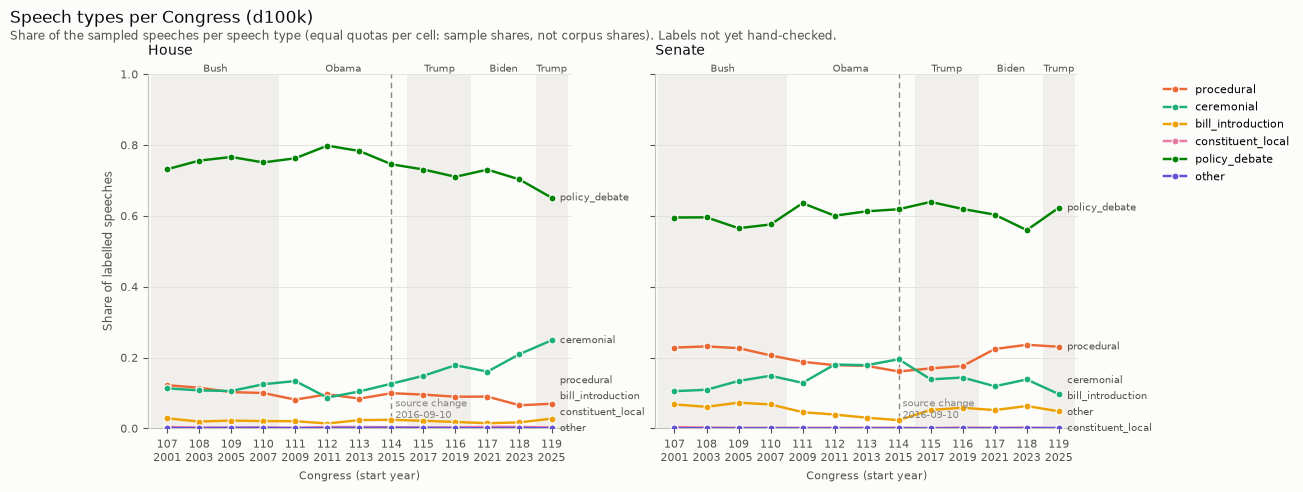

Speech-type shares (%) by chamber and source:


speech_type       procedural  ceremonial  bill_introduction  \
chamber source                                                
H       govinfo          8.2        19.0                2.0   
        stanford        10.0        11.1                2.2   
S       govinfo         20.6        13.0                5.4   
        stanford        20.0        14.6                5.1   

speech_type       constituent_local  policy_debate  other  
chamber source                                             
H       govinfo                 0.4           70.5    0.1  
        stanford                0.3           76.3    0.1  
S       govinfo                 0.2           60.7    0.1  
        stanford                0.2           60.1    0.0

In [16]:
type_shares = label_shares(df, ["congress_number", "chamber"])
fig = plot_label_shares(
    type_shares,
    "Speech types per Congress (d100k)",
    subtitle="Share of the sampled speeches per speech type (equal quotas per cell: sample shares, not corpus shares). Labels not yet hand-checked.",
    order=SPEECH_TYPES,
)
save_figure(fig, "d100k_label_type_shares")
plt.show()

print("Speech-type shares (%) by chamber and source:")
(pd.crosstab([df["chamber"], df["source"]], df["speech_type"], normalize="index") * 100).round(1)[list(SPEECH_TYPES)]

In [17]:
display(procedural_crosstab(df))
scores_by_type(df)

procedural,all models 0.0,scored,All
speech_type,,,
(no label),21,8,29
bill_introduction,1557,2097,3654
ceremonial,10671,3406,14077
constituent_local,158,91,249
other,56,12,68
policy_debate,12907,54246,67153
procedural,13504,1262,14766
All,38874,61122,99996


,chamber,speech_type,n,mean_abs_ideology,mean_ideology,mean_tone,procedural_share
0,H,bill_introduction,1040,0.116,-2.875e-02,0.033,0.650
1,H,ceremonial,7101,0.091,-1.338e-02,0.025,0.763
2,H,constituent_local,159,0.117,-8.616e-02,0.055,0.623
3,H,other,48,0.078,4.479e-02,0.128,0.792
4,H,policy_debate,36997,0.462,-1.664e-02,0.382,0.191
5,H,procedural,4649,0.055,5.836e-03,0.062,0.859
6,S,bill_introduction,2614,0.282,-1.707e-01,0.068,0.337
7,S,ceremonial,6976,0.091,-1.621e-02,0.023,0.753
8,S,constituent_local,90,0.126,-1.006e-01,0.028,0.656
9,S,other,20,0.055,1.000e-02,0.135,0.900


**Reading it.** The S8 picture holds with far more speeches: the Senate's
speech-type mix is the same in both sources (policy debate 60.1% → 60.7%, procedural
20.0% → 20.6%), while the House's shifts — ceremonial 11.1% → 19.0%, policy debate
76.3% → 70.5%. **With one model, the 0.0 flag is an even weaker stand-in for
"procedural"**: it catches 91% of the speeches labelled procedural, but also 76% of
the ceremonial ones and **19% of the policy debates** (12,907; 10% in S8, where both
models had to score 0.0). Excluding by the flag would drop a fifth of the policy
debates; excluding by label would not (O12).

**Within topic.** The gap per topic block before and after the 115th Congress
(2017), and the topic mix in each period, on policy debates.

In [18]:
policy = policy.assign(
    period=policy["congress_number"].le(SOURCE_BREAK_CONGRESS).map(
        {True: "107th–114th (2001–2016)", False: "115th–119th (2017–2025)"}
    )
)
block_cells = cell_means(policy, by=("period", "chamber", "topic_block", "party"))
block_gaps = party_gap(block_cells, by=("period", "chamber", "topic_block"))
print("Party gap (R − D) per topic block, with 95% intervals clustered by member:")
display(block_gaps.assign(gap_ci=with_ci(block_gaps, "gap")).pivot(
    index=["chamber", "topic_block"], columns="period", values="gap_ci"
))
print("Fewest speeches in any party cell:", int(block_cells["n"].min()))
print("Topic-block shares of policy debate (%), by period:")
(pd.crosstab([policy["chamber"], policy["period"]], policy["topic_block"], normalize="index") * 100).round(1)

Party gap (R − D) per topic block, with 95% intervals clustered by member:


period                   107th–114th (2001–2016) 115th–119th (2017–2025)
chamber topic_block                                                     
H       economic            +0.88 [+0.85, +0.92]    +1.01 [+0.97, +1.05]
        governance          +0.52 [+0.48, +0.57]    +0.79 [+0.73, +0.84]
        other               +0.35 [+0.32, +0.39]    +0.37 [+0.33, +0.41]
        security_foreign    +0.49 [+0.45, +0.54]    +0.56 [+0.51, +0.61]
        social_cultural     +0.97 [+0.92, +1.03]    +1.33 [+1.30, +1.37]
S       economic            +0.85 [+0.79, +0.92]    +1.16 [+1.08, +1.24]
        governance          +0.46 [+0.42, +0.51]    +0.91 [+0.85, +0.98]
        other               +0.34 [+0.29, +0.39]    +0.42 [+0.34, +0.49]
        security_foreign    +0.49 [+0.42, +0.55]    +0.68 [+0.60, +0.77]
        social_cultural     +0.80 [+0.61, +0.99]    +1.35 [+1.28, +1.41]

Fewest speeches in any party cell: 275
Topic-block shares of policy debate (%), by period:


topic_block                      economic  governance  other  \
chamber period                                                 
H       107th–114th (2001–2016)      52.9         5.9    8.6   
        115th–119th (2017–2025)      45.1        10.6    7.3   
S       107th–114th (2001–2016)      48.6        13.5    7.3   
        115th–119th (2017–2025)      40.5        20.3    5.4   

topic_block                      security_foreign  social_cultural  
chamber period                                                      
H       107th–114th (2001–2016)              22.1             10.5  
        115th–119th (2017–2025)              18.9             18.0  
S       107th–114th (2001–2016)              20.3             10.2  
        115th–119th (2017–2025)              20.0             13.9

**Reading it.** With at least 275 speeches in every party cell, the
within-topic picture is firm. **The gap widens inside topics:** in the Senate in every
block (economic 0.85 → 1.16, governance 0.46 → 0.91, security/foreign 0.49 → 0.68,
social-cultural 0.80 → 1.35; "other" 0.34 → 0.42 with overlapping intervals), in the
House in economic (0.88 → 1.01), governance (0.52 → 0.79) and social-cultural issues
(0.97 → 1.33), while security/foreign (0.49 → 0.56) and "other" barely move. **And the
agenda shifts toward the most divided blocks:** social-cultural issues grow from 10.5%
to 18.0% of House policy debate (Senate 10.2% → 13.9%), governance from 5.9% to 10.6%
(Senate 13.5% → 20.3%), while economic debate falls (House 52.9% → 45.1%, Senate
48.6% → 40.5%). Both drive the wider gap; a decomposition with intervals would say
how much each.

**Saving the tables.** The numbers behind the figures, to `results/metrics/`
(committed).

In [19]:
tables = {
    "ideology_cells": cells,
    "party_gap": gaps,
    "ideology_trends": trends,
    "party_gap_policy_only": gaps_policy,
    "ideology_trends_policy_only": trends_policy,
    "tone_cells": tone_cells,
    "tone_by_opposition": opposition,
    "member_validation": members,
    "label_type_shares": type_shares,
    "party_gap_by_topic_block": block_gaps,
    "build_comparison_shift": shift.groupby(["source", "chamber", "party"])[["ideology", "tone"]].mean().reset_index(),
}
for name, table in tables.items():
    path = METRICS_DIR / f"d100k_{name}_{RUN}.csv"
    table.to_csv(path, index=False)
    print(path.relative_to(ROOT))

results/metrics/d100k_ideology_cells_20261018T122536Z.csv
results/metrics/d100k_party_gap_20261018T122536Z.csv
results/metrics/d100k_ideology_trends_20261018T122536Z.csv
results/metrics/d100k_party_gap_policy_only_20261018T122536Z.csv
results/metrics/d100k_ideology_trends_policy_only_20261018T122536Z.csv
results/metrics/d100k_tone_cells_20261018T122536Z.csv
results/metrics/d100k_tone_by_opposition_20261018T122536Z.csv
results/metrics/d100k_member_validation_20261018T122536Z.csv
results/metrics/d100k_label_type_shares_20261018T122536Z.csv
results/metrics/d100k_party_gap_by_topic_block_20261018T122536Z.csv
results/metrics/d100k_build_comparison_shift_20261018T122536Z.csv


## 10. Caveats and open questions

- **Preliminary.** For discussion; none of these figures is final.
- **One model** (S19). There is no cross-provider check inside this run; the evidence
  that a second model tells the same story is S8 (r = 0.94 with GPT-4o, section 2).
  GPT-4o puts the parties further apart, so levels depend on the model.
- **A newer DeepSeek build than S8** (V4.1-Flash-1017; S18, P7). Levels are not
  interchangeable with S8's (section 2); trends within this run are unaffected.
- **The 2016 source break.** govinfo yields fewer speeches per year than Stanford
  (O8); the 114th mixes both, and its govinfo part is only September–December 2016.
  2001–2016 is the clean window.
- **Equal quotas per cell.** Every Congress × party × chamber cell has 1,923
  speeches, so pooled figures and label shares are sample figures, not corpus ones.
- **Speeches, not members.** Frequent speakers weigh more; member-level averaging is
  in section 6 (O9, settled since by A5: member × Congress means, Nokken-Poole, within cells).
- **The labels are not yet hand-checked** (L4), use codebook v1, and leave 29
  speeches unlabelled. Which speeches to exclude as non-substantive is open (O12).
- **Tone and ideology come from one model reading the same text.**
- **No temperature** (S2a): a re-run would differ somewhat speech by speech.
- **The 119th Congress covers 2025 only.**